# CSE 366: Artificial Intelligence / Machine Learning Project
## Submission 3: Custom CNN Built from Scratch
**Group 3 · Department of CSE, East West University**
**Domain:** Precision agriculture and computer vision for foliar disease diagnosis
**Dataset:** PlantVillage (Kaggle `emmarex/plantdisease`), the same 15-class subset as Submission 1: Pepper (2 classes), Potato (3) and Tomato (10), 20,638 RGB leaf images

### What this notebook delivers (roadmap, Submission 3)
| Requirement | Where |
|---|---|
| Multiple convolutional and pooling layers, ending in a fully connected layer | Section 5: 5 conv layers, 4 max-pool layers, global average pooling, 2 fully connected layers |
| ReLU and batch normalisation | every convolution is Conv → BatchNorm → ReLU |
| Proper preprocessing and data augmentation | Sections 2 and 3 |
| Consistent hyperparameters | one configuration table, Section 6 |
| Monitor train and validation loss; early stopping, at least 5 epochs | Section 6 (early stopping patience 7, never before epoch 10) |
| Accuracy, precision, recall, F1, confusion matrix, training and testing time | Section 7 |

---
## 1. Environment and configuration
Every submission uses the same configuration, the same random seed and the same stratified 70/15/15 split, so results are comparable across notebooks.

> **Compute note.** This notebook was executed on a CPU-only machine (2 cores, no GPU). To keep the full protocol feasible there, images are resized to **64 × 64** instead of the usual 224 × 224. The only thing to change for a higher-resolution run on a GPU (for example Google Colab) is `IMG_SIZE` in the cell below; the image cache is rebuilt automatically.

In [1]:
# ---- Imports, configuration and reproducibility (identical in every submission) ----
import os, sys, time, json, copy, math, random, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as tvm
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except Exception:                       # plain-python fallback
    display = lambda obj: print(obj.to_string() if hasattr(obj, "to_string") else obj)

# ------------------------- Global configuration -------------------------
SEED       = 42        # seed for the data split and for training
IMG_SIZE   = 64        # input resolution (64 keeps CPU training feasible; use 128 or 224 on a GPU)
BATCH_SIZE = 64
VAL_FRAC   = 0.15      # stratified 70 / 15 / 15 split
TEST_FRAC  = 0.15
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count() or 2)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# ------------------------- Plot theme (soft pastel palette) -------------------------
PAL = {"rose": "#E7A3B6", "mint": "#A9D9C3", "blue": "#A8C8E8", "yellow": "#F4DC8A",
       "rose_d": "#C25A7B", "mint_d": "#4E9E7E", "blue_d": "#4A7FB5", "yellow_d": "#C79D1E",
       "ink": "#3B3B4F", "grid": "#E6E2EA"}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 110, "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.edgecolor": PAL["ink"], "axes.labelcolor": PAL["ink"], "text.color": PAL["ink"],
    "xtick.color": PAL["ink"], "ytick.color": PAL["ink"], "axes.grid": True,
    "grid.color": PAL["grid"], "axes.facecolor": "#FFFEFC", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False})
CM_CMAP   = LinearSegmentedColormap.from_list("pastel_cm",   ["#FFFFFF", PAL["blue"], PAL["blue_d"]])
HEAT_CMAP = LinearSegmentedColormap.from_list("pastel_heat", [PAL["rose"], PAL["yellow"], PAL["mint"]])

print(f"PyTorch {torch.__version__} | device: {DEVICE} | CPU threads: {torch.get_num_threads()} "
      f"| input size: {IMG_SIZE}x{IMG_SIZE} | batch size: {BATCH_SIZE} | seed: {SEED}")

PyTorch 2.14.1+cpu | device: cpu | CPU threads: 2 | input size: 64x64 | batch size: 64 | seed: 42


---
## 2. Dataset, preprocessing and split
The dataset is loaded from the Kaggle archive used in Submission 1 (folders `archive/PlantVillage/<class>/`). A zero-byte placeholder file in the Yellow Leaf Curl Virus folder is skipped, which gives exactly the **20,638** images counted in Submission 1.

* **Resize:** 256 × 256 → `IMG_SIZE` × `IMG_SIZE` (bilinear); **Normalise:** ImageNet mean and standard deviation (as planned in Submission 1, and required by the pretrained backbones).
* **Stratified 70 / 15 / 15 split** with a fixed seed, so every class appears in train, validation and test in the same proportion.
* **Class weights:** inverse-frequency weights in the loss counter the 21 : 1 imbalance found in the EDA (smallest class: Potato healthy, 152 images).

In [2]:
# ---- Load PlantVillage (same 15 classes as Submission 1) and build the shared split ----
SHORT = {
    "Pepper__bell___Bacterial_spot": "Pepper Bacterial spot", "Pepper__bell___healthy": "Pepper healthy",
    "Potato___Early_blight": "Potato Early blight", "Potato___Late_blight": "Potato Late blight",
    "Potato___healthy": "Potato healthy", "Tomato_Bacterial_spot": "Tomato Bacterial spot",
    "Tomato_Early_blight": "Tomato Early blight", "Tomato_Late_blight": "Tomato Late blight",
    "Tomato_Leaf_Mold": "Tomato Leaf mold", "Tomato_Septoria_leaf_spot": "Tomato Septoria spot",
    "Tomato_Spider_mites_Two_spotted_spider_mite": "Tomato Spider mites",
    "Tomato__Target_Spot": "Tomato Target spot", "Tomato__Tomato_YellowLeaf__Curl_Virus": "Tomato Yellow leaf curl",
    "Tomato__Tomato_mosaic_virus": "Tomato Mosaic virus", "Tomato_healthy": "Tomato healthy"}
IMG_EXT = {".jpg", ".jpeg", ".png"}
CACHE_DIR = Path(os.environ.get("PV_CACHE_DIR", "."))

def _is_dataset_dir(p):
    return p.is_dir() and sum(d.is_dir() for d in p.iterdir()) >= 15

def find_dataset_dir():
    candidates = [os.environ.get("PV_DATA_DIR", ""), "/content/archive/PlantVillage", "/content/PlantVillage",
                  "/content/drive/MyDrive/PlantVillage", "/content/drive/MyDrive/archive/PlantVillage",
                  "archive/PlantVillage", "PlantVillage", "../archive/PlantVillage", "data/PlantVillage"]
    for c in candidates:
        if c and _is_dataset_dir(Path(c)):
            return Path(c)
    try:  # Colab or any machine with internet access: fetch the same Kaggle dataset
        import kagglehub
        root = Path(kagglehub.dataset_download("emmarex/plantdisease"))
        for p in [root / "PlantVillage", *root.rglob("PlantVillage")]:
            if _is_dataset_dir(p):
                return p
    except Exception as e:
        print("kagglehub download failed:", e)
    raise FileNotFoundError("PlantVillage folder not found. Download 'emmarex/plantdisease' from Kaggle "
                            "and place it at archive/PlantVillage (or set PV_DATA_DIR).")

def build_cache(data_dir, img_size, cache_path):
    class_dirs = [d for d in sorted(data_dir.iterdir()) if d.is_dir() and d.name != "PlantVillage"]
    X, y, names = [], [], [d.name for d in class_dirs]
    for ci, d in enumerate(class_dirs):
        files = sorted(f for f in d.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXT and f.stat().st_size > 0)
        for f in files:
            with Image.open(f) as im:
                X.append(np.asarray(im.convert("RGB").resize((img_size, img_size), Image.Resampling.BILINEAR)))
            y.append(ci)
        print(f"  loaded {len(files):5d} images  <-  {d.name}")
    np.savez(cache_path, X=np.stack(X).astype(np.uint8), y=np.array(y, dtype=np.int64), names=np.array(names))

DATA_DIR = find_dataset_dir()
print("Active dataset directory:", DATA_DIR)
cache_path = CACHE_DIR / f"plantvillage_{IMG_SIZE}px.npz"
if not cache_path.exists():
    print(f"Building a {IMG_SIZE}x{IMG_SIZE} image cache (one-off) ...")
    t0 = time.time(); build_cache(DATA_DIR, IMG_SIZE, cache_path); print(f"cache built in {time.time()-t0:.0f}s")
z = np.load(cache_path)
X_all, y_all, CLASS_NAMES = z["X"], z["y"], [str(n) for n in z["names"]]
NUM_CLASSES = len(CLASS_NAMES)
LABELS = [SHORT.get(n, n.replace("_", " ")) for n in CLASS_NAMES]
print(f"\nImages: {len(y_all):,} | classes: {NUM_CLASSES} | tensor shape per image: {tuple(X_all.shape[1:])} (H, W, RGB)")

# ---- Stratified 70 / 15 / 15 split (fixed seed, so every submission uses the same test set) ----
idx_all = np.arange(len(y_all))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=VAL_FRAC + TEST_FRAC, stratify=y_all, random_state=SEED)
idx_va, idx_te = train_test_split(idx_tmp, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
                                  stratify=y_all[idx_tmp], random_state=SEED)
assert not (set(idx_tr) & set(idx_va)) and not (set(idx_tr) & set(idx_te)) and not (set(idx_va) & set(idx_te))

def to_tensor(idx):
    return torch.from_numpy(X_all[idx]).permute(0, 3, 1, 2).contiguous(), torch.from_numpy(y_all[idx])
X_tr, y_tr = to_tensor(idx_tr); X_va, y_va = to_tensor(idx_va); X_te, y_te = to_tensor(idx_te)

split_df = pd.DataFrame({"Class": LABELS,
                         "Train": np.bincount(y_tr.numpy(), minlength=NUM_CLASSES),
                         "Val":   np.bincount(y_va.numpy(), minlength=NUM_CLASSES),
                         "Test":  np.bincount(y_te.numpy(), minlength=NUM_CLASSES)})
split_df["Total"] = split_df[["Train", "Val", "Test"]].sum(axis=1)
split_df.loc[len(split_df)] = ["ALL CLASSES", *split_df[["Train", "Val", "Test", "Total"]].sum().tolist()]
print(f"\nStratified split -> train {len(y_tr):,} | validation {len(y_va):,} | test {len(y_te):,}")
display(split_df)

# ---- Class weights (inverse frequency) to counter the 21:1 imbalance found in the EDA ----
train_counts = np.bincount(y_tr.numpy(), minlength=NUM_CLASSES)
CLASS_W = torch.tensor(len(y_tr) / (NUM_CLASSES * train_counts), dtype=torch.float32)
print("\nClass weights (largest for the rarest classes):")
print(pd.Series(CLASS_W.numpy().round(2), index=LABELS).sort_values(ascending=False).head(5).to_string())

Active dataset directory: archive/PlantVillage



Images: 20,638 | classes: 15 | tensor shape per image: (64, 64, 3) (H, W, RGB)



Stratified split -> train 14,446 | validation 3,096 | test 3,096


,Class,Train,Val,Test,Total
0,Pepper Bacterial spot,698,150,149,997
1,Pepper healthy,1035,222,221,1478
2,Potato Early blight,700,150,150,1000
3,Potato Late blight,700,150,150,1000
4,Potato healthy,106,23,23,152
5,Tomato Bacterial spot,1489,319,319,2127
6,Tomato Early blight,700,150,150,1000
7,Tomato Late blight,1336,286,287,1909
8,Tomato Leaf mold,666,143,143,952
9,Tomato Septoria spot,1240,265,266,1771



Class weights (largest for the rarest classes):
Potato healthy         9.09
Tomato Mosaic virus    3.69
Tomato Leaf mold       1.45
Tomato Early blight    1.38
Potato Late blight     1.38


---
## 3. Data augmentation and the training loop
Augmentation is implemented as fast batch operations on the training images only (validation and test images are never augmented). The transforms follow the plan written in Submission 1, scaled to the lower resolution:

| Type | Setting |
|---|---|
| Flips | horizontal and vertical, p = 0.5 each |
| Rotation | ±30° (reflection padding) |
| Zoom / random crop | keeps 80–100 % of the field of view, random position |
| Photometric | brightness, contrast and saturation ±20 % |
| Random erasing | p = 0.2, noise-filled rectangle covering 2–15 % of the image |

In [3]:
# ---- Preprocessing, data augmentation and the shared training loop ----
MEAN = torch.tensor(IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor(IMAGENET_STD,  device=DEVICE).view(1, 3, 1, 1)

def prep_eval(xb):
    """uint8 [B,3,H,W] -> ImageNet-normalised float tensor (no augmentation)."""
    return (xb.float() / 255.0 - MEAN) / STD

def augment(x):
    """Batch augmentation on float images in [0,1]; follows the plan written in Submission 1:
    flips (p=0.5), rotation +-30 deg, random zoom/crop (scale 0.8-1.0), brightness/contrast/saturation +-0.2,
    random erasing (p=0.2)."""
    B, _, H, W = x.shape; dev = x.device
    x = torch.where((torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1), x.flip(3), x)       # horizontal flip
    x = torch.where((torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1), x.flip(2), x)       # vertical flip
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(30)                              # rotation
    s = torch.empty(B, device=dev).uniform_(0.8, 1.0)                                          # zoom (fraction of view kept)
    tx = (torch.rand(B, device=dev) * 2 - 1) * (1 - s); ty = (torch.rand(B, device=dev) * 2 - 1) * (1 - s)
    cos, sin = torch.cos(ang) * s, torch.sin(ang) * s
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False),
                      mode="bilinear", padding_mode="reflection", align_corners=False)
    jit = lambda: 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.2                      # +-20 %
    x = x * jit()                                                                              # brightness
    m = x.mean(dim=(1, 2, 3), keepdim=True); x = (x - m) * jit() + m                           # contrast
    g = x.mean(dim=1, keepdim=True); x = (x - g) * jit() + g                                   # saturation
    x = x.clamp(0, 1)
    area = torch.empty(B, device=dev).uniform_(0.02, 0.15) * H * W                             # random erasing
    ratio = torch.empty(B, device=dev).uniform_(0.3, 3.3)
    eh = (area * ratio).sqrt().clamp(1, H).long(); ew = (area / ratio).sqrt().clamp(1, W).long()
    y0 = (torch.rand(B, device=dev) * (H - eh + 1)).long(); x0 = (torch.rand(B, device=dev) * (W - ew + 1)).long()
    ys = torch.arange(H, device=dev).view(1, H, 1); xs = torch.arange(W, device=dev).view(1, 1, W)
    box = (ys >= y0.view(B, 1, 1)) & (ys < (y0 + eh).view(B, 1, 1)) & (xs >= x0.view(B, 1, 1)) & (xs < (x0 + ew).view(B, 1, 1))
    box = box & (torch.rand(B, device=dev) < 0.2).view(B, 1, 1)
    return torch.where(box.unsqueeze(1), torch.rand_like(x), x)

def prep_train(xb):
    return (augment(xb.float() / 255.0) - MEAN) / STD

identity = lambda t: t   # used when the inputs are already feature vectors

class Logger:
    """Prints and records every line so a finished experiment can be replayed from disk."""
    def __init__(self): self.lines = []
    def __call__(self, s=""): print(s, flush=True); self.lines.append(str(s))

def channels_last(model):
    """Use the channels-last memory layout (about 1.3-1.5x faster on CPU for small / depthwise networks; same results)."""
    model.to(memory_format=torch.channels_last)
    for m in model.modules(): m._cl = True
    return model

def _fmt(x, model):
    return x.contiguous(memory_format=torch.channels_last) if getattr(model, "_cl", False) and x.dim() == 4 else x

def _sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def evaluate(model, X, y, loss_fn, prep, bs=256):
    """Loss and accuracy on a split (used for validation after every epoch)."""
    model.eval(); tot, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(_fmt(prep(X[i:i + bs].to(DEVICE)), model)); yb = y[i:i + bs].to(DEVICE)
        tot += loss_fn(out, yb).item() * len(yb); correct += (out.argmax(1) == yb).sum().item()
    return tot / len(X), correct / len(X)

@torch.no_grad()
def predict_timed(model, X, prep, bs=256):
    """Predictions plus the wall-clock time of the forward passes (= testing time)."""
    model.eval(); preds = []; _sync(); t0 = time.perf_counter()
    for i in range(0, len(X), bs):
        preds.append(model(_fmt(prep(X[i:i + bs].to(DEVICE)), model)).argmax(1).cpu())
    _sync(); return torch.cat(preds).numpy(), time.perf_counter() - t0

def fit(model, data, epochs, optimizer, loss_fn, train_prep, eval_prep, scheduler=None, plateau=False,
        patience=None, min_epochs=5, seed=SEED, log=print):
    """Train for up to `epochs`; keep the weights of the best validation loss.
    Early stopping triggers after `patience` epochs without improvement (never before `min_epochs`)."""
    Xtr, ytr, Xva, yva = data
    model.to(DEVICE)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr", "epoch_sec"]}
    best = {"val_loss": float("inf"), "epoch": 0, "state": None}; bad = 0; stopped_early = False
    gen = torch.Generator().manual_seed(seed)
    _sync(); t_fit = time.perf_counter()
    for ep in range(1, epochs + 1):
        t_ep = time.perf_counter(); model.train()
        perm = torch.randperm(len(Xtr), generator=gen)
        run_loss = run_ok = seen = 0
        for i in range(0, len(perm), BATCH_SIZE):
            bi = perm[i:i + BATCH_SIZE]
            if len(bi) < 2: continue                      # BatchNorm needs more than one sample
            xb = _fmt(train_prep(Xtr[bi].to(DEVICE)), model); yb = ytr[bi].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            out = model(xb); loss = loss_fn(out, yb); loss.backward(); optimizer.step()
            run_loss += loss.item() * len(bi); run_ok += (out.argmax(1) == yb).sum().item(); seen += len(bi)
        vl, va = evaluate(model, Xva, yva, loss_fn, eval_prep)
        lr_now = optimizer.param_groups[0]["lr"]
        if scheduler is not None:
            scheduler.step(vl) if plateau else scheduler.step()
        _sync(); sec = time.perf_counter() - t_ep
        for k, v in zip(hist, [run_loss / seen, run_ok / seen, vl, va, lr_now, sec]): hist[k].append(v)
        if vl < best["val_loss"] - 1e-4:
            best.update(val_loss=vl, epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}); bad = 0
        else:
            bad += 1
        log(f"Epoch {ep:02d}/{epochs} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f} | "
            f"val loss {vl:.4f} acc {va:.4f} | lr {lr_now:.1e} | {sec:5.1f}s" + ("  *best*" if best["epoch"] == ep else ""))
        if patience is not None and bad >= patience and ep >= min_epochs:
            stopped_early = True; log(f"Early stopping at epoch {ep}: no val-loss improvement for {patience} epochs "
                                      f"(best epoch = {best['epoch']})."); break
    _sync(); train_sec = time.perf_counter() - t_fit
    model.load_state_dict(best["state"])                  # restore the best checkpoint
    return {"hist": hist, "best_epoch": best["epoch"], "epochs_run": len(hist["val_loss"]),
            "train_sec": train_sec, "stopped_early": stopped_early}

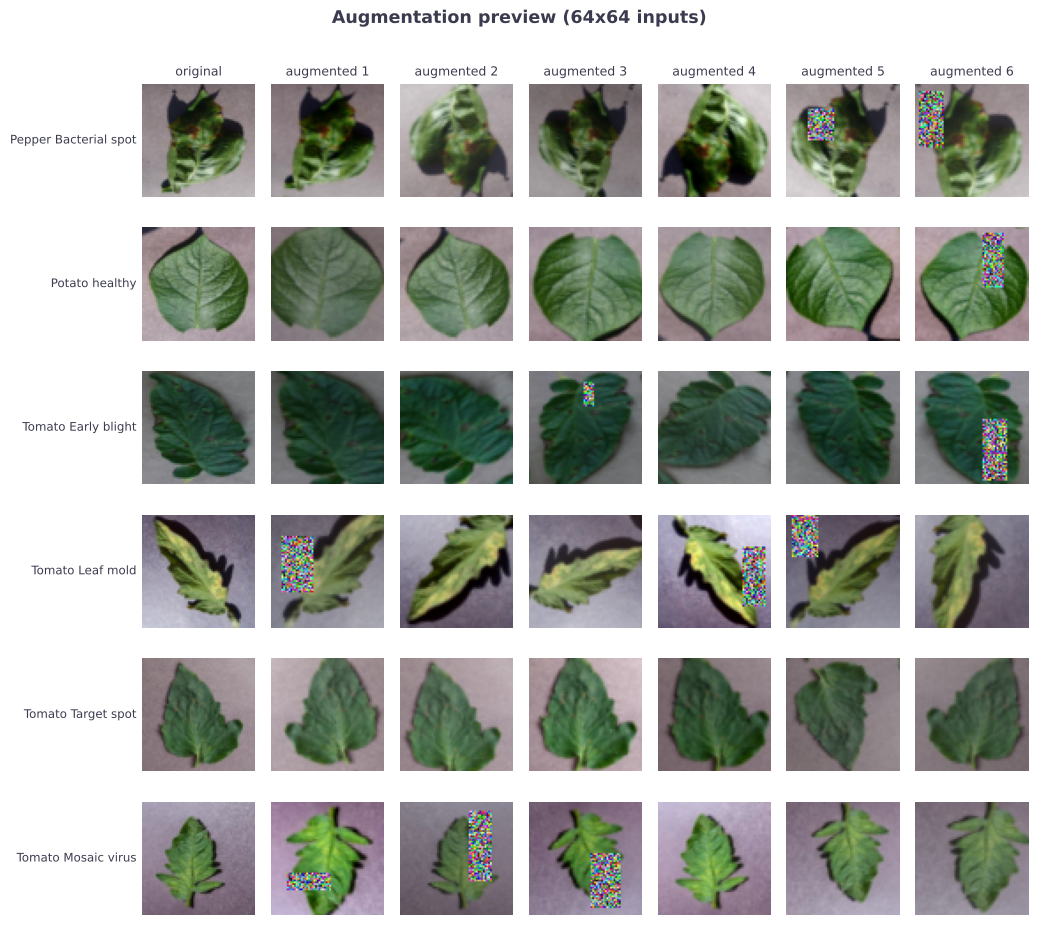

In [4]:
# ---- Preview of the augmentation pipeline (applied to training images only) ----
set_seed(SEED)
shown = [int(np.where(y_tr.numpy() == c)[0][0]) for c in (0, 4, 6, 8, 11, 13)]
fig, axes = plt.subplots(len(shown), 7, figsize=(10.5, 1.55 * len(shown)))
for r, i in enumerate(shown):
    base = X_tr[i:i + 1].to(DEVICE)
    axes[r, 0].imshow(base[0].permute(1, 2, 0).cpu().numpy())
    axes[r, 0].set_ylabel(LABELS[int(y_tr[i])], rotation=0, ha="right", va="center", fontsize=8.5)
    for c in range(1, 7):
        axes[r, c].imshow(augment(base.float() / 255.0)[0].permute(1, 2, 0).cpu().numpy())
    for c in range(7):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
        for s in axes[r, c].spines.values(): s.set_visible(False)
    if r == 0:
        axes[r, 0].set_title("original", fontsize=9)
        for c in range(1, 7): axes[r, c].set_title(f"augmented {c}", fontsize=9)
plt.suptitle(f"Augmentation preview ({IMG_SIZE}x{IMG_SIZE} inputs)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

---
## 4. Evaluation utilities
The same code is used in all submissions. The training loop (`fit`) trains with a validation pass after every epoch and keeps the weights of the epoch with the lowest validation loss. `report_experiment` prints accuracy, precision, recall and F1 (macro and weighted), the per-class classification report, **training time** and **testing time**, then draws the accuracy and loss curves and the confusion matrix.

In [5]:
# ---- Evaluation helpers: metrics, classification report, curves, confusion matrix ----
RESULT_DIR = Path(os.environ.get("PV_RESULT_DIR", "results")); RESULT_DIR.mkdir(exist_ok=True, parents=True)
RESUME = os.environ.get("PV_RESUME", "0") == "1"      # only used to continue an interrupted run

def count_params(model):
    tot = sum(p.numel() for p in model.parameters()); trn = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return tot, trn

def metric_row(y_true, y_pred):
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision_macro": pm, "recall_macro": rm, "f1_macro": fm,
            "precision_weighted": pw, "recall_weighted": rw, "f1_weighted": fw}

def plot_curves(hist, title, best_epoch=None):
    ep = np.arange(1, len(hist["val_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
    for a, k, name in [(ax[0], "acc", "Accuracy"), (ax[1], "loss", "Loss")]:
        a.plot(ep, hist[f"train_{k}"], color=PAL["rose_d"], lw=2, marker="o", ms=3, label="train")
        a.plot(ep, hist[f"val_{k}"], color=PAL["blue_d"], lw=2, marker="o", ms=3, label="validation")
        if best_epoch: a.axvline(best_epoch, color=PAL["yellow_d"], ls="--", lw=1.4, label=f"best epoch ({best_epoch})")
        a.set_xlabel("epoch"); a.set_ylabel(name); a.set_title(f"{name} curve"); a.legend(frameon=False)
        a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    fig.suptitle(title, fontweight="bold", y=1.03); plt.tight_layout(); plt.show()

def plot_confusion(cm, title, fontsize=7.5):
    fig, ax = plt.subplots(figsize=(10.5, 8.6))
    ax.imshow(cm, cmap=CM_CMAP, vmin=0, vmax=max(1, cm.max())); ax.grid(False)
    ax.set_xticks(range(len(LABELS))); ax.set_yticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=55, ha="right", fontsize=8.5); ax.set_yticklabels(LABELS, fontsize=8.5)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]:
                ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=fontsize,
                        color="white" if cm[i, j] > 0.55 * cm.max() else PAL["ink"])
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title, fontweight="bold")
    for s in ax.spines.values(): s.set_visible(True)
    plt.tight_layout(); plt.show()

def report_experiment(rec, show_plots=True):
    """Print metrics + classification report and draw curves and the confusion matrix for one finished experiment."""
    m = rec["metrics"]
    print(f"=== {rec['name']} ===")
    print(f"Parameters: {rec['params_total']:,} total, {rec['params_trainable']:,} trainable | "
          f"epochs run: {rec['epochs_run']} | best epoch (lowest val loss): {rec['best_epoch']}"
          + (" | stopped early" if rec.get("stopped_early") else ""))
    print(f"Accuracy {m['accuracy']:.4f} | Precision(macro) {m['precision_macro']:.4f} | Recall(macro) {m['recall_macro']:.4f} | "
          f"F1(macro) {m['f1_macro']:.4f} | F1(weighted) {m['f1_weighted']:.4f}")
    print(f"Training time: {rec['train_sec']:.1f} s ({rec['train_sec']/60:.1f} min) | "
          f"Testing time: {rec['test_sec']:.2f} s for {rec['n_test']:,} test images ({1000*rec['test_sec']/rec['n_test']:.2f} ms/image)\n")
    print("Classification report (test set):"); print(rec["report"])
    if show_plots:
        plot_curves(rec["hist"], f"{rec['name']}: training vs validation", rec["best_epoch"])
        plot_confusion(rec["cm"], f"{rec['name']}: confusion matrix (test set, n={rec['n_test']:,})")

def make_record(name, model, fit_out, y_true, y_pred, test_sec, log, **extra):
    tot, trn = count_params(model)
    rec = {"name": name, "hist": fit_out["hist"], "best_epoch": fit_out["best_epoch"], "epochs_run": fit_out["epochs_run"],
           "stopped_early": fit_out["stopped_early"], "train_sec": fit_out["train_sec"] + extra.pop("extra_train_sec", 0.0),
           "test_sec": test_sec, "n_test": len(y_true), "params_total": tot, "params_trainable": trn,
           "metrics": metric_row(y_true, y_pred), "cm": confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES)),
           "y_pred": np.asarray(y_pred), "y_true": np.asarray(y_true),
           "report": classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=LABELS, digits=4, zero_division=0),
           "per_class_f1": precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)[2],
           "log": list(log.lines)}
    rec.update(extra); return rec

def save_record(rec, fname):
    with open(RESULT_DIR / fname, "wb") as f: pickle.dump(rec, f)

def load_record(fname):
    with open(RESULT_DIR / fname, "rb") as f: return pickle.load(f)

def top_confusions(cm, k=8):
    """The k most frequent mistakes (true class -> predicted class)."""
    off = cm.copy(); np.fill_diagonal(off, 0)
    order = np.argsort(-off.ravel())[:k]
    rows = [{"True class": LABELS[i], "Predicted as": LABELS[j], "Images": int(off[i, j])}
            for i, j in zip(*np.unravel_index(order, off.shape)) if off[i, j] > 0]
    return pd.DataFrame(rows)

---
## 5. Architecture
A compact network sized for 64 × 64 inputs. Filters double after every pooling step (16 → 32 → 64 → 128), which keeps the cost low while still building from edges and colour blobs to lesion-level patterns.

| Stage | Layers | Output (64 px input) |
|---|---|---|
| 1 | Conv 3×3 (16) · BN · ReLU · MaxPool 2 | 16 × 32 × 32 |
| 2 | Conv 3×3 (32) · BN · ReLU · MaxPool 2 | 32 × 16 × 16 |
| 3 | Conv 3×3 (64) · BN · ReLU · MaxPool 2 | 64 × 8 × 8 |
| 4 | Conv 3×3 (128) · BN · ReLU · Conv 3×3 (128) · BN · ReLU | 128 × 8 × 8 |
| Head | MaxPool 2 · global average pool · Dropout 0.3 · FC 128→128 · ReLU · Dropout 0.3 · FC 128→15 | 15 logits |

Batch normalisation stabilises training from scratch, dropout (0.3) and weight decay regularise the fully connected part, and global average pooling avoids a huge dense layer.

In [6]:
# ---- Custom CNN (built from scratch) and its training recipe ----
class ConvBlock(nn.Sequential):
    """3x3 convolution -> batch normalisation -> ReLU."""
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class CustomCNN(nn.Module):
    """5 conv layers + 4 max-pool layers + global average pooling + fully connected classifier.
    `attention_factory` (used only in Submission 4) inserts ONE attention module after the last conv block;
    it is created last, so every other layer gets exactly the same initial weights with or without it."""
    def __init__(self, num_classes=NUM_CLASSES, attention_factory=None):
        super().__init__()
        self.stage1 = nn.Sequential(ConvBlock(3, 16), nn.MaxPool2d(2))                  # 64 -> 32
        self.stage2 = nn.Sequential(ConvBlock(16, 32), nn.MaxPool2d(2))                 # 32 -> 16
        self.stage3 = nn.Sequential(ConvBlock(32, 64), nn.MaxPool2d(2))                 # 16 -> 8
        self.stage4 = nn.Sequential(ConvBlock(64, 128), ConvBlock(128, 128))             # 8 x 8
        self.pool = nn.Sequential(nn.MaxPool2d(2), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, 128), nn.ReLU(inplace=True),
                                        nn.Dropout(0.3), nn.Linear(128, num_classes))
        self.attention = attention_factory(128) if attention_factory else nn.Identity()  # created last on purpose

    def forward(self, x):
        x = self.stage3(self.stage2(self.stage1(x)))
        x = self.attention(self.stage4(x))
        return self.classifier(self.pool(x))

def layer_table(model):
    """Output shape and parameter count of every conv / pool / linear / attention layer."""
    rows, hooks = [], []
    def hook(name):
        def fn(m, inp, out):
            rows.append({"Layer": name, "Type": type(m).__name__, "Output shape": tuple(out.shape[1:]),
                         "Params": sum(p.numel() for p in m.parameters())})
        return fn
    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.AdaptiveAvgPool2d, nn.Linear)) or type(m).__name__ in ("CBAM", "SEBlock"):
            hooks.append(m.register_forward_hook(hook(name)))
    model.eval()
    with torch.no_grad(): model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=next(model.parameters()).device))
    for h in hooks: h.remove()
    return pd.DataFrame(rows)

# ---- Identical training recipe for every custom-CNN run (Submissions 3 and 4) ----
LOSS_FN = nn.CrossEntropyLoss(weight=CLASS_W.to(DEVICE))          # class-weighted cross-entropy
CFG = dict(optimizer="AdamW", lr=1e-3, weight_decay=1e-4, batch_size=BATCH_SIZE, max_epochs=40,
           early_stopping_patience=7, min_epochs=10, lr_schedule="ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-5)",
           loss="class-weighted cross-entropy", augmentation="flips, rotation, zoom, colour jitter, random erasing")

def train_custom(name, attention_factory=None, seed=SEED, fname=None):
    if RESUME and fname and (RESULT_DIR / fname).exists():
        rec = load_record(fname); [print(l) for l in rec["log"]]; return rec
    set_seed(seed); log = Logger()
    model = channels_last(CustomCNN(attention_factory=attention_factory).to(DEVICE))
    tot, trn = count_params(model); log(f"{name} | seed {seed} | {tot:,} parameters")
    set_seed(seed)                                                  # same batch order / augmentation / dropout for every variant
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=3, min_lr=1e-5)
    out = fit(model, (X_tr, y_tr, X_va, y_va), CFG["max_epochs"], opt, LOSS_FN, prep_train, prep_eval, scheduler=sched,
              plateau=True, patience=CFG["early_stopping_patience"], min_epochs=CFG["min_epochs"], seed=seed, log=log)
    y_pred, t_test = predict_timed(model, X_te, prep_eval)
    rec = make_record(name, model, out, y_te.numpy(), y_pred, t_test, log, seed=seed)
    rec["state"] = {k: v.cpu() for k, v in model.state_dict().items()}
    if fname: save_record(rec, fname)
    return rec

_m = CustomCNN().to(DEVICE)
print(_m)
tot, _ = count_params(_m); print(f"\nTotal trainable parameters: {tot:,}")
display(layer_table(_m))

CustomCNN(
  (stage1): Sequential(
    (0): ConvBlock(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (stage2): Sequential(
    (0): ConvBlock(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (stage3): Sequential(
    (0): ConvBlock(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
 

,Layer,Type,Output shape,Params
0,stage1.0.0,Conv2d,"(16, 64, 64)",432
1,stage1.1,MaxPool2d,"(16, 32, 32)",0
2,stage2.0.0,Conv2d,"(32, 32, 32)",4608
3,stage2.1,MaxPool2d,"(32, 16, 16)",0
4,stage3.0.0,Conv2d,"(64, 16, 16)",18432
5,stage3.1,MaxPool2d,"(64, 8, 8)",0
6,stage4.0.0,Conv2d,"(128, 8, 8)",73728
7,stage4.1.0,Conv2d,"(128, 8, 8)",147456
8,pool.0,MaxPool2d,"(128, 4, 4)",0
9,pool.1,AdaptiveAvgPool2d,"(128, 1, 1)",0


---
## 6. Training setup
All hyperparameters are fixed in the `CFG` dictionary and are reused unchanged in Submission 4.

* **Optimiser:** AdamW, learning rate 1e-3, weight decay 1e-4, batch size 64
* **Loss:** class-weighted cross-entropy (handles the class imbalance)
* **Learning-rate schedule:** halve the rate when the validation loss has not improved for 3 epochs
* **Early stopping:** stop when the validation loss has not improved for **7** epochs, but never before epoch **10** (the roadmap minimum is 5); maximum 40 epochs; the best-validation-loss weights are restored
* **Monitoring:** training and validation loss and accuracy are logged and plotted every epoch

In [7]:
print(json.dumps(CFG, indent=2))

{
  "optimizer": "AdamW",
  "lr": 0.001,
  "weight_decay": 0.0001,
  "batch_size": 64,
  "max_epochs": 40,
  "early_stopping_patience": 7,
  "min_epochs": 10,
  "lr_schedule": "ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-5)",
  "loss": "class-weighted cross-entropy",
  "augmentation": "flips, rotation, zoom, colour jitter, random erasing"
}


---
## 7. Training and evaluation

Custom CNN (from scratch) | seed 42 | 263,839 parameters


Epoch 01/40 | train loss 1.8310 acc 0.4111 | val loss 1.3738 acc 0.5352 | lr 1.0e-03 |  27.8s  *best*


Epoch 02/40 | train loss 1.2035 acc 0.5924 | val loss 1.1437 acc 0.6047 | lr 1.0e-03 |  25.8s  *best*


Epoch 03/40 | train loss 0.9447 acc 0.6752 | val loss 0.6069 acc 0.7729 | lr 1.0e-03 |  27.4s  *best*


Epoch 04/40 | train loss 0.7750 acc 0.7338 | val loss 0.7036 acc 0.7594 | lr 1.0e-03 |  27.5s


...

Epoch 29/40 | train loss 0.1958 acc 0.9325 | val loss 0.1924 acc 0.9238 | lr 1.3e-04 |  26.9s


Epoch 30/40 | train loss 0.1831 acc 0.9335 | val loss 0.1874 acc 0.9267 | lr 1.3e-04 |  26.2s


Epoch 31/40 | train loss 0.1901 acc 0.9337 | val loss 0.3056 acc 0.8908 | lr 1.3e-04 |  27.2s


Early stopping at epoch 31: no val-loss improvement for 7 epochs (best epoch = 24).


=== Custom CNN (from scratch) ===
Parameters: 263,839 total, 263,839 trainable | epochs run: 31 | best epoch (lowest val loss): 24 | stopped early
Accuracy 0.9325 | Precision(macro) 0.8993 | Recall(macro) 0.9426 | F1(macro) 0.9135 | F1(weighted) 0.9331
Training time: 828.9 s (13.8 min) | Testing time: 1.64 s for 3,096 test images (0.53 ms/image)

Classification report (test set):
                         precision    recall  f1-score   support

  Pepper Bacterial spot     1.0000    0.9396    0.9689       149
         Pepper healthy     1.0000    0.9276    0.9624       221
    Potato Early blight     0.9613    0.9933    0.9770       150
     Potato Late blight     0.8402    0.9467    0.8903       150
         Potato healthy     0.5227    1.0000    0.6866        23
  Tomato Bacterial spot     0.9430    0.9342    0.9386       319
    Tomato Early blight     0.8571    0.9200    0.8875       150
     Tomato Late blight     0.9867    0.7735    0.8672       287
       Tomato Leaf mold     0.9

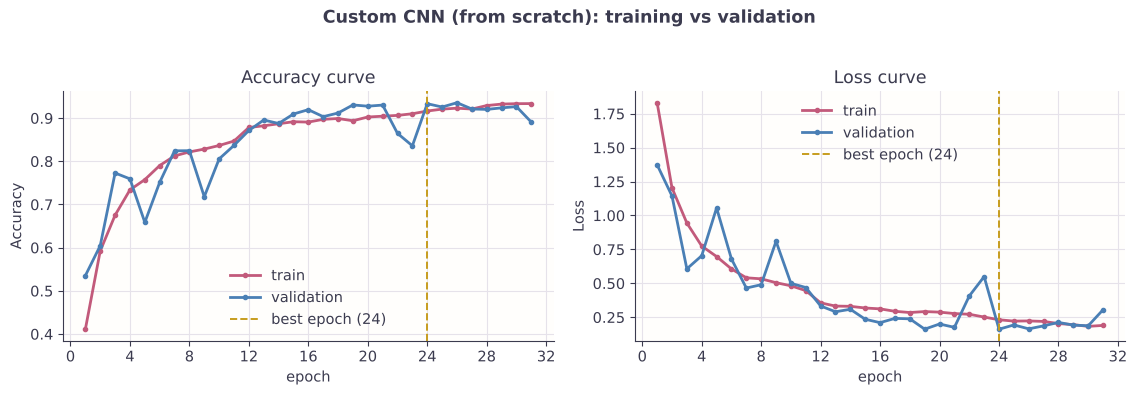

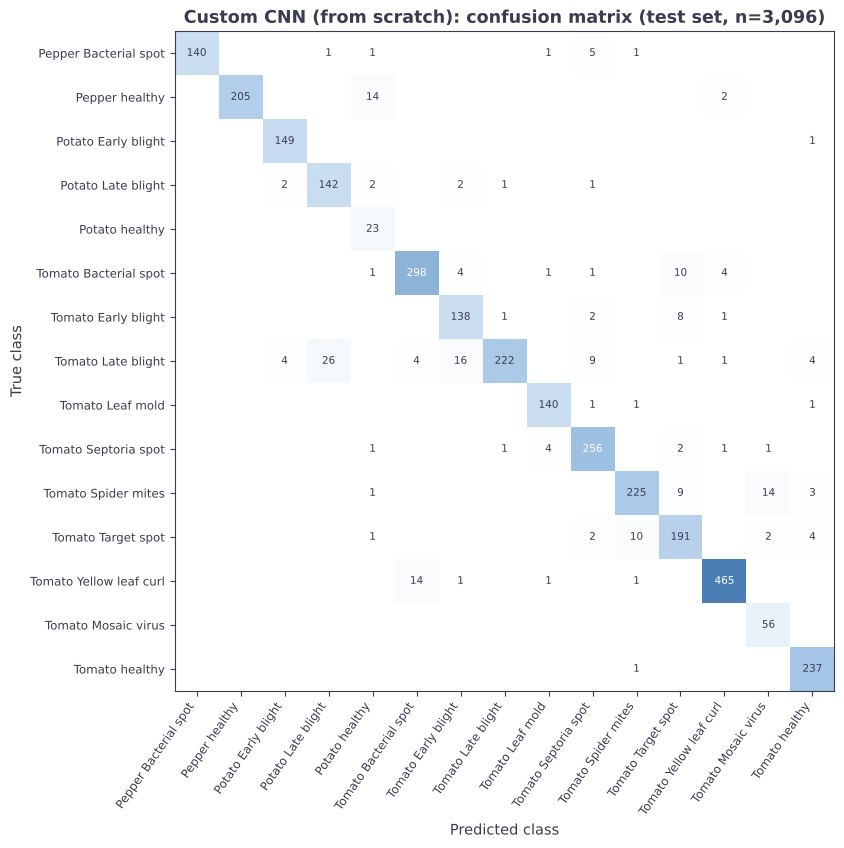

In [8]:
baseline = train_custom("Custom CNN (from scratch)", None, seed=SEED, fname="s3_baseline_seed42.pkl")
report_experiment(baseline)

### Most frequent mistakes on the test set

In [9]:
display(top_confusions(baseline["cm"], k=10))

,True class,Predicted as,Images
0,Tomato Late blight,Potato Late blight,26
1,Tomato Late blight,Tomato Early blight,16
2,Pepper healthy,Potato healthy,14
3,Tomato Yellow leaf curl,Tomato Bacterial spot,14
4,Tomato Spider mites,Tomato Mosaic virus,14
5,Tomato Target spot,Tomato Spider mites,10
6,Tomato Bacterial spot,Tomato Target spot,10
7,Tomato Late blight,Tomato Septoria spot,9
8,Tomato Spider mites,Tomato Target spot,9
9,Tomato Early blight,Tomato Target spot,8


### 8. Analysis

**Result.** The custom CNN (5 convolution layers, 4 max-pool layers, global average pooling, 263,839 parameters) reaches **test accuracy 0.9325, macro-F1 0.9135, macro-precision 0.8993, macro-recall 0.9426, weighted-F1 0.9331**. Training stopped early at epoch 31 (best validation loss at epoch 24) after about 13.8 min; testing 3,096 images took 1.64 s (0.53 ms/image).

**Over-/under-fitting.** At the best epoch the training accuracy (0.916, measured on augmented batches) is slightly *below* validation accuracy (0.934),. This is a mild **underfit, not an overfit**: the augmentation, dropout and class weighting make training harder than evaluation. Early stopping and the plateau scheduler were only needed to pick a stable checkpoint; validation accuracy dipped to 0.836 in epochs 22 and 23 before recovering, which shows the learning rate was still noisy at that point.

**Where it fails.** The most frequent mistakes are visually similar classes: Tomato Late blight → Potato Late blight (26 images), Tomato Late blight → Tomato Early blight (16), Pepper healthy → Potato healthy (14), Tomato Yellow leaf curl → Tomato Bacterial spot (14) and Tomato Spider mites → Tomato Mosaic virus (14). At 64×64 pixels small lesions and fine texture are partly lost, which explains most of these. **Potato healthy** has recall 1.00 but precision 0.52: with only 152 images it receives the largest class weight (about 9×), so the model over-predicts it. The weights helped recall of rare classes but cost precision; a milder weight (for example the square root of the inverse frequency) is a reasonable next experiment.

**Compared with the other submissions.** Better than every frozen pretrained model (0.82 to 0.87), worse than every fine-tuned one (0.965 to 0.980), but with only 0.26 M parameters.

**Ideas to improve.** Larger input size (the `IMG_SIZE` constant), a milder class weight, more epochs with a cosine schedule, or an attention block (Submission 4).

---
## Submission checklist
* [x] Custom CNN: 5 convolutional layers, 4 pooling layers, global average pooling and fully connected layers
* [x] ReLU activations and batch normalisation in every convolutional block
* [x] Preprocessing (resize, ImageNet normalisation) and data augmentation, previewed visually
* [x] Consistent hyperparameters in one configuration table
* [x] Training and validation loss monitored every epoch, early stopping (minimum 10 epochs, above the required 5)
* [x] Accuracy, precision, recall, F1, confusion matrix, training time and testing time reported

All cells were run top to bottom before saving, so every table and plot is visible in this notebook.